# Friendship communities and artist recommendation

This notebook studies whether friendship communities add useful information to a Last.fm recommender. I build the analysis step by step from the original HetRec 2011 data.

## 1. Load the data

The three tables used here contain artists, user–artist listening counts, and friendship links. The listening counts are implicit feedback: a larger count means stronger evidence of interest, but not an explicit rating.

In [1]:
import os
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"

from hashlib import sha256
from math import ceil, floor, log2
from pathlib import Path
import random
from time import perf_counter
import warnings
from zipfile import ZipFile

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import sparse
from implicit.cpu.als import AlternatingLeastSquares

SEED = 5101
plt.style.use("seaborn-v0_8-whitegrid")
pd.options.display.float_format = "{:.8f}".format

In [2]:
archive_path = Path("data/raw/hetrec2011-lastfm-2k.zip")

with ZipFile(archive_path) as archive:
    artists = pd.read_csv(archive.open("artists.dat"), sep="	")
    listens = pd.read_csv(archive.open("user_artists.dat"), sep="	")
    friends = pd.read_csv(archive.open("user_friends.dat"), sep="	")

artists = artists.rename(columns={"id": "artist_id", "pictureURL": "picture_url"})
listens = listens.rename(columns={"userID": "user_id", "artistID": "artist_id"})
friends = friends.rename(columns={"userID": "user_id", "friendID": "friend_id"})

artists["artist_id"] = artists["artist_id"].astype("int64")
listens = listens.astype("int64")
friends = friends.astype("int64")

In [3]:
display(listens.head())
display(friends.head())
display(artists.head())

,user_id,artist_id,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


,user_id,friend_id
0,2,275
1,2,428
2,2,515
3,2,761
4,2,831


,artist_id,name,url,picture_url
0,1,MALICE MIZER,http://www.last.fm/music/MALICE+MIZER,http://userserve-ak.last.fm/serve/252/10808.jpg
1,2,Diary of Dreams,http://www.last.fm/music/Diary+of+Dreams,http://userserve-ak.last.fm/serve/252/3052066.jpg
2,3,Carpathian Forest,http://www.last.fm/music/Carpathian+Forest,http://userserve-ak.last.fm/serve/252/40222717...
3,4,Moi dix Mois,http://www.last.fm/music/Moi+dix+Mois,http://userserve-ak.last.fm/serve/252/54697835...
4,5,Bella Morte,http://www.last.fm/music/Bella+Morte,http://userserve-ak.last.fm/serve/252/14789013...


In [4]:
shape_summary = pd.DataFrame({
    "table": ["listens", "friends", "artists"],
    "rows": [len(listens), len(friends), len(artists)],
    "columns": [listens.shape[1], friends.shape[1], artists.shape[1]],
})

missing_summary = pd.concat({
    "listens": listens.isna().sum(),
    "friends": friends.isna().sum(),
    "artists": artists.isna().sum(),
}).rename("missing_values").to_frame()

display(shape_summary)
display(missing_summary)

,table,rows,columns
0,listens,92834,3
1,friends,25434,2
2,artists,17632,4


missing_values
listens user_id                   0
        artist_id                 0
        weight                    0
friends user_id                   0
        friend_id                 0
artists artist_id                 0
        name                      0
        url                       0
        picture_url             444

In [5]:
undirected_friends = pd.DataFrame({
    "user_1": friends[["user_id", "friend_id"]].min(axis=1),
    "user_2": friends[["user_id", "friend_id"]].max(axis=1),
}).drop_duplicates().sort_values(["user_1", "user_2"], ignore_index=True)

print(f"Users: {listens.user_id.nunique():,}")
print(f"Artists with listens: {listens.artist_id.nunique():,}")
print(f"Unique friendships: {len(undirected_friends):,}")

Users: 1,892
Artists with listens: 17,632
Unique friendships: 12,717


## 2. Train, validation and test split

Users with at least seven artists receive a 70/15/15 split. Shorter histories stay in the fitting data. To keep the split reproducible, I order each user's rows with the SHA-256 value of `5101|user_id|artist_id`, then use largest-remainder allocation. This row-ordering rule is kept unchanged from the earlier analysis.

In [6]:
def allocation_counts(n):
    proportions = (0.70, 0.15, 0.15)
    quotas = [p * n for p in proportions]
    counts = [floor(q) for q in quotas]
    order = sorted(range(3), key=lambda i: (-(quotas[i] - counts[i]), i))
    for i in order[:n - sum(counts)]:
        counts[i] += 1
    return tuple(counts)


def row_key(user_id, artist_id):
    text = f"{SEED}|{user_id}|{artist_id}".encode("ascii")
    return sha256(text).digest(), artist_id

In [7]:
assignments = []
partition_names = ("train", "validation", "test")

for user_id, group in listens.groupby("user_id", sort=True):
    rows = [(int(row.artist_id), int(row.weight)) for row in group.itertuples()]
    rows = sorted(rows, key=lambda row: row_key(int(user_id), row[0]))
    if len(rows) < 7:
        assignments.extend((user_id, artist, weight, "train_only_low_history")
                           for artist, weight in rows)
        continue
    start = 0
    for name, count in zip(partition_names, allocation_counts(len(rows))):
        assignments.extend((user_id, artist, weight, name)
                           for artist, weight in rows[start:start + count])
        start += count

split_table = pd.DataFrame(assignments, columns=["user_id", "artist_id", "weight", "split"])
split_table = split_table.sort_values(["user_id", "artist_id"], ignore_index=True)

,split,rows,users
0,train,64958,1876
1,validation,14842,1876
2,test,12996,1876
3,train_only_low_history,38,16


Training-history first-quartile cutoff: 35 artists
Users at or below the cutoff: 1,876 of 1,876


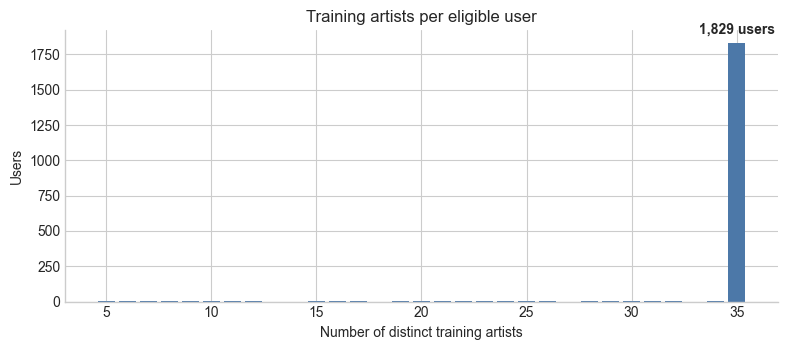

In [8]:
split_summary = (split_table.groupby("split")
                 .agg(rows=("artist_id", "size"), users=("user_id", "nunique"))
                 .reindex(["train", "validation", "test", "train_only_low_history"])
                 .reset_index())
display(split_summary)

train_counts = split_table.query("split == 'train'").groupby("user_id").artist_id.nunique()
eligible_users = sorted(train_counts.index)
cutoff_rank = ceil(0.25 * len(train_counts))
sparse_cutoff = int(train_counts.sort_values().iloc[cutoff_rank - 1])
sparse_flags = train_counts.le(sparse_cutoff)
print(f"Training-history first-quartile cutoff: {sparse_cutoff} artists")
print(f"Users at or below the cutoff: {sparse_flags.sum():,} of {len(sparse_flags):,}")

history_distribution = train_counts.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(history_distribution.index, history_distribution.values, color="#4C78A8")
users_at_35 = int(history_distribution.get(35, 0))
ax.annotate(f"{users_at_35:,} users", (35, users_at_35), xytext=(0, 7),
            textcoords="offset points", ha="center", fontweight="bold")
ax.set(title="Training artists per eligible user",
       xlabel="Number of distinct training artists", ylabel="Users")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

Most eligible users are concentrated at the upper end of the training-history distribution: 1,829 have exactly 35 training artists. Because the first-quartile cutoff is also 35 and ties are included, all 1,876 eligible users are classified as sparse, leaving no non-sparse group for a meaningful subgroup comparison.

## 3. Friendship communities

I treat friendship as an undirected graph and use NetworkX's Louvain method with seed 5101. Isolated users are included as graph nodes. Community labels use the smallest user ID in each group so that the labels are easy to reproduce.

In [9]:
graph = nx.Graph()
graph.add_nodes_from(sorted(listens.user_id.unique()))
graph.add_edges_from(undirected_friends.itertuples(index=False, name=None))

groups = nx.community.louvain_communities(graph, seed=SEED)
groups = sorted([tuple(sorted(group)) for group in groups], key=lambda group: group[0])
membership = pd.DataFrame(
    [(user_id, group[0]) for group in groups for user_id in group],
    columns=["user_id", "community_id"],
).sort_values("user_id", ignore_index=True)

modularity = nx.community.modularity(graph, [set(group) for group in groups])
community_sizes = sorted([len(group) for group in groups], reverse=True)
print(f"Communities: {len(groups)}")
print(f"Modularity: {modularity:.4f}")

Communities: 32
Modularity: 0.4526


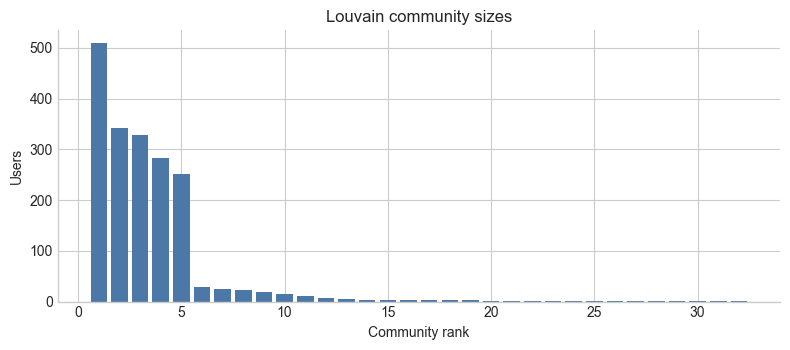

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(range(1, len(community_sizes) + 1), community_sizes, color="#4C78A8")
ax.set(title="Louvain community sizes", xlabel="Community rank", ylabel="Users")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Recommendation methods

Listening counts are transformed with $\log(1+w)$. The community model estimates an artist's activity share inside each community and shrinks it towards the global share using $\beta$. ALS uses confidence $1+\alpha\log(1+w)$; these complete confidence values are placed directly in the sparse matrix, so the library's own `alpha` is left at 1.

The hybrid z-scores the finite ALS and community log-scores within each user's candidate set, then combines them with weight $\lambda$ on ALS. All methods rank the same candidates for a given evaluation.

In [11]:
def fit_community_profile(fit, member_table, beta):
    table = fit[["user_id", "artist_id", "weight"]].copy()
    table["activity"] = np.log1p(table["weight"])
    universe = tuple(sorted(table.artist_id.unique()))
    totals = table.groupby("artist_id").activity.sum()
    global_share = {artist: float(totals.get(artist, 0) / totals.sum()) for artist in universe}

    joined = table.merge(member_table, on="user_id", how="left")
    community_total = joined.groupby("community_id").activity.sum()
    community_artist = joined.groupby(["community_id", "artist_id"]).activity.sum()
    scores = {}
    for community_id in sorted(member_table.community_id.unique()):
        mass = float(community_total.get(community_id, 0))
        scores[community_id] = {
            artist: float((community_artist.get((community_id, artist), 0) +
                           beta * global_share[artist]) / (mass + beta))
            for artist in universe
        }
    return {"scores": scores, "global": global_share, "universe": universe}

In [12]:
def fit_als(fit, factors, regularization, alpha):
    user_ids = tuple(sorted(fit.user_id.unique()))
    artist_ids = tuple(sorted(fit.artist_id.unique()))
    user_index = {user_id: i for i, user_id in enumerate(user_ids)}
    artist_index = {artist_id: i for i, artist_id in enumerate(artist_ids)}

    rows = fit.user_id.map(user_index).to_numpy(dtype=np.int32)
    cols = fit.artist_id.map(artist_index).to_numpy(dtype=np.int32)
    confidence = 1 + alpha * np.log1p(fit.weight.to_numpy(dtype=float))
    matrix = sparse.coo_matrix(
        (confidence.astype(np.float32), (rows, cols)),
        shape=(len(user_ids), len(artist_ids)), dtype=np.float32,
    ).tocsr()
    matrix.sort_indices()

    model = AlternatingLeastSquares(
        factors=factors, regularization=regularization, alpha=1.0,
        iterations=20, random_state=SEED, dtype=np.float32, num_threads=1,
    )
    model.fit(matrix, show_progress=False)
    return {"model": model, "users": user_index, "artists": artist_index}

In [13]:
def als_scores(fitted, user_id, candidates):
    scores = np.full(len(candidates), -np.inf)
    user_position = fitted["users"].get(int(user_id))
    item_positions = np.array([fitted["artists"].get(int(a), -1) for a in candidates])
    available = item_positions >= 0
    if user_position is not None:
        scores[available] = (fitted["model"].item_factors[item_positions[available]] @
                             fitted["model"].user_factors[user_position])
    return scores


def community_scores(profile, member_map, user_id, candidates):
    probabilities = profile["scores"].get(member_map[int(user_id)], profile["global"])
    values = np.array([probabilities.get(int(a), 0.0) for a in candidates])
    return np.log(values, out=np.full(len(values), -np.inf), where=values > 0)

In [14]:
def zscore_finite(values):
    result = np.full(len(values), -np.inf)
    finite = np.isfinite(values)
    standard_deviation = values[finite].std(ddof=0)
    if standard_deviation == 0:
        result[finite] = 0
    else:
        result[finite] = (values[finite] - values[finite].mean()) / standard_deviation
    return result


def hybrid_scores(als_values, community_values, lambda_):
    als_z = zscore_finite(als_values)
    community_z = zscore_finite(community_values)
    shared = np.isfinite(als_z) & np.isfinite(community_z)
    result = np.full(len(als_values), -np.inf)
    result[shared] = lambda_ * als_z[shared] + (1 - lambda_) * community_z[shared]
    return result

In [15]:
def ranking_metrics(candidates, scores, relevant, k=10):
    finite = np.isfinite(scores)
    order = np.lexsort((candidates, -np.where(finite, scores, 0), ~finite))
    ranked = candidates[order[:k]]
    relevant = set(relevant)
    dcg = sum(1 / log2(rank + 1) for rank, artist in enumerate(ranked, 1)
              if int(artist) in relevant)
    idcg = sum(1 / log2(rank + 1) for rank in range(1, min(k, len(relevant)) + 1))
    recall = len(set(ranked) & relevant) / len(relevant)
    return float(dcg / idcg), float(recall), ranked

In [16]:
def build_phase(split_data, phase, candidate_universe=None):
    fit_names = ["train", "train_only_low_history"]
    if phase == "test":
        fit_names.append("validation")
    fit = split_data[split_data.split.isin(fit_names)].copy()
    learned_universe = tuple(sorted(fit.artist_id.unique()))
    universe = learned_universe if candidate_universe is None else tuple(sorted(candidate_universe))
    fit_by_user = {int(u): set(g.artist_id) for u, g in fit.groupby("user_id")}
    heldout = split_data[split_data.split == phase]
    heldout_by_user = {int(u): set(g.artist_id) for u, g in heldout.groupby("user_id")}

    users = []
    universe_set = set(universe)
    for user_id in sorted(heldout_by_user):
        candidates = universe_set - fit_by_user.get(user_id, set())
        if heldout_by_user[user_id] & candidates:
            users.append(user_id)
    cold_pairs = sum(len(values - set(learned_universe)) for values in heldout_by_user.values())
    return {"fit": fit, "universe": universe, "learned_universe": learned_universe,
            "fit_by_user": fit_by_user, "heldout": heldout_by_user,
            "users": tuple(users), "cold_pairs": cold_pairs, "phase": phase}

In [17]:
def evaluate(phase_data, score_function):
    rows, recommended = [], set()
    missing_scores = 0
    universe = phase_data["universe"]
    for user_id in phase_data["users"]:
        seen = phase_data["fit_by_user"].get(user_id, set())
        candidates = np.array([a for a in universe if a not in seen], dtype=np.int64)
        relevant = phase_data["heldout"][user_id] & set(candidates)
        scores = np.asarray(score_function(user_id, candidates), dtype=float)
        ndcg, recall, ranked = ranking_metrics(candidates, scores, relevant)
        rows.append((user_id, ndcg, recall))
        recommended.update(ranked)
        missing_scores += int((~np.isfinite(scores)).sum())

    per_user = pd.DataFrame(rows, columns=["user_id", "ndcg_at_10", "recall_at_10"])
    return {
        "ndcg_at_10": float(per_user.ndcg_at_10.mean()),
        "recall_at_10": float(per_user.recall_at_10.mean()),
        "coverage_at_10": len(recommended) / len(universe),
        "per_user": per_user,
        "missing_scores": missing_scores,
        "users": len(per_user),
    }

## 5. Validation and model selection

Validation NDCG@10 is the selection metric. I compare eight ALS settings, three community shrinkage values, and nine hybrid settings. Test rows are not used in this step.

In [18]:
validation_phase = build_phase(split_table, "validation")
member_map = membership.set_index("user_id").community_id.to_dict()
validation_rows = []
als_models = {}
validation_started = perf_counter()

for factors in (32, 64):
    for regularization in (0.01, 0.10):
        for alpha in (1.0, 10.0):
            fitted = fit_als(validation_phase["fit"], factors, regularization, alpha)
            result = evaluate(validation_phase,
                              lambda user, candidates, m=fitted: als_scores(m, user, candidates))
            als_models[(factors, regularization, alpha)] = fitted
            validation_rows.append({"method": "ALS", "factors": factors,
                                    "regularization": regularization, "alpha": alpha,
                                    "beta": np.nan, "lambda": np.nan, **result})

In [19]:
validation_table = pd.DataFrame(validation_rows)
best_als_row = (validation_table.sort_values(
    ["ndcg_at_10", "factors", "regularization", "alpha"],
    ascending=[False, True, False, True]).iloc[0])
best_als_key = (int(best_als_row.factors), float(best_als_row.regularization),
                float(best_als_row.alpha))
selected_validation_als = als_models[best_als_key]

community_profiles = {}
for beta in (10.0, 100.0, 1000.0):
    profile = fit_community_profile(validation_phase["fit"], membership, beta)
    community_profiles[beta] = profile
    result = evaluate(validation_phase,
                      lambda user, candidates, p=profile:
                      community_scores(p, member_map, user, candidates))
    validation_rows.append({"method": "Community", "factors": np.nan,
                            "regularization": np.nan, "alpha": np.nan,
                            "beta": beta, "lambda": np.nan, **result})

In [20]:
for beta, profile in community_profiles.items():
    for lambda_ in (0.25, 0.50, 0.75):
        def score_hybrid(user, candidates, p=profile, weight=lambda_):
            left = als_scores(selected_validation_als, user, candidates)
            right = community_scores(p, member_map, user, candidates)
            return hybrid_scores(left, right, weight)

        result = evaluate(validation_phase, score_hybrid)
        validation_rows.append({"method": "Hybrid", "factors": np.nan,
                                "regularization": np.nan, "alpha": np.nan,
                                "beta": beta, "lambda": lambda_, **result})

validation_table = pd.DataFrame(validation_rows)
print(f"Validation completed in {perf_counter() - validation_started:.1f} seconds")
display(validation_table[["method", "factors", "regularization", "alpha", "beta", "lambda",
                          "ndcg_at_10", "recall_at_10", "users"]].round(6))

Validation completed in 147.0 seconds


,method,factors,regularization,alpha,beta,lambda,ndcg_at_10,recall_at_10,users
0,ALS,32.00000000,0.01000000,1.00000000,NaN,NaN,0.19747000,0.19516800,1873
1,ALS,32.00000000,0.01000000,10.00000000,NaN,NaN,0.16137700,0.16964400,1873
2,ALS,32.00000000,0.10000000,1.00000000,NaN,NaN,0.19766500,0.19537500,1873
3,ALS,32.00000000,0.10000000,10.00000000,NaN,NaN,0.16218000,0.17166100,1873
4,ALS,64.00000000,0.01000000,1.00000000,NaN,NaN,0.18820300,0.18652500,1873
5,ALS,64.00000000,0.01000000,10.00000000,NaN,NaN,0.15737900,0.16415500,1873
6,ALS,64.00000000,0.10000000,1.00000000,NaN,NaN,0.18868800,0.18689200,1873
7,ALS,64.00000000,0.10000000,10.00000000,NaN,NaN,0.15911000,0.16640300,1873
8,Community,NaN,NaN,NaN,10.00000000,NaN,0.11679900,0.11117600,1873
9,Community,NaN,NaN,NaN,100.00000000,NaN,0.11671700,0.11110900,1873


,method,parameters
0,ALS,"factors=32, reg=0.1, alpha=1.0"
1,Community,beta=1000
2,Hybrid,"beta=100, lambda=0.25"


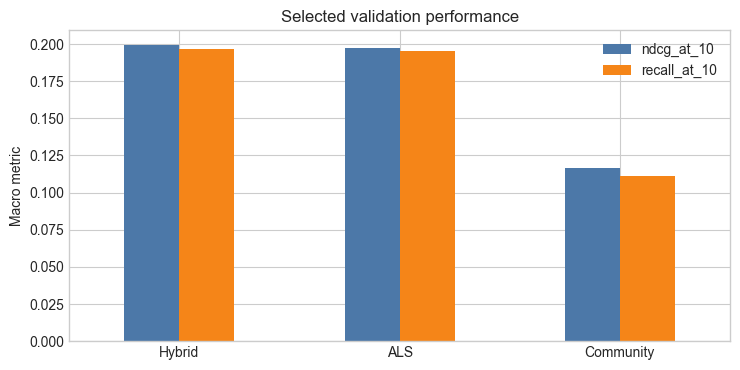

In [21]:
best_community_row = (validation_table.query("method == 'Community'")
                      .sort_values(["ndcg_at_10", "beta"], ascending=[False, True]).iloc[0])
best_hybrid_row = (validation_table.query("method == 'Hybrid'")
                   .sort_values(["ndcg_at_10", "beta", "lambda"],
                                ascending=[False, True, True]).iloc[0])

selected = pd.DataFrame([
    {"method": "ALS", "parameters": f"factors={best_als_key[0]}, reg={best_als_key[1]}, alpha={best_als_key[2]}"},
    {"method": "Community", "parameters": f"beta={best_community_row.beta:g}"},
    {"method": "Hybrid", "parameters": f"beta={best_hybrid_row.beta:g}, lambda={best_hybrid_row['lambda']:g}"},
])
display(selected)

best_validation = (validation_table.sort_values("ndcg_at_10", ascending=False)
                   .groupby("method", sort=False).first()[["ndcg_at_10", "recall_at_10"]])
best_validation.plot.bar(figsize=(7.5, 3.8), color=["#4C78A8", "#F58518"])
plt.title("Selected validation performance"); plt.xlabel(""); plt.ylabel("Macro metric")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 6. Final test comparison

After choosing the parameters, I add validation rows to the fitting data and refit the models. Each test user's candidate set contains fitting-observed artists that the user has not already listened to. Relevance is the intersection of held-out artists with this set.

In [22]:
test_phase = build_phase(split_table, "test")
selected_beta = float(best_community_row.beta)
hybrid_beta = float(best_hybrid_row.beta)
selected_lambda = float(best_hybrid_row["lambda"])

final_als = fit_als(test_phase["fit"], *best_als_key)
community_profile = fit_community_profile(test_phase["fit"], membership, selected_beta)
hybrid_profile = fit_community_profile(test_phase["fit"], membership, hybrid_beta)

fit_activity = test_phase["fit"].assign(
    activity=np.log1p(test_phase["fit"].weight)
).groupby("artist_id").activity.sum().to_dict()

In [23]:
scorers = {
    "Global popularity": lambda user, candidates:
        np.array([fit_activity.get(int(a), 0.0) for a in candidates]),
    "ALS": lambda user, candidates: als_scores(final_als, user, candidates),
    "Community": lambda user, candidates:
        community_scores(community_profile, member_map, user, candidates),
    "Hybrid": lambda user, candidates: hybrid_scores(
        als_scores(final_als, user, candidates),
        community_scores(hybrid_profile, member_map, user, candidates), selected_lambda),
}

test_results = {name: evaluate(test_phase, scorer) for name, scorer in scorers.items()}
test_metrics = pd.DataFrame([
    {"method": name, "NDCG@10": result["ndcg_at_10"],
     "Recall@10": result["recall_at_10"], "Coverage@10": result["coverage_at_10"],
     "users": result["users"], "cold held-out pairs": test_phase["cold_pairs"]}
    for name, result in test_results.items()
])
display(test_metrics.round(8))

,method,NDCG@10,Recall@10,Coverage@10,users,cold held-out pairs
0,Global popularity,0.07807618,0.08156924,0.00180607,1872,1635
1,ALS,0.23932421,0.23364621,0.05007162,1872,1635
2,Community,0.13195566,0.12580891,0.02086317,1872,1635
3,Hybrid,0.24190366,0.23354446,0.04776733,1872,1635


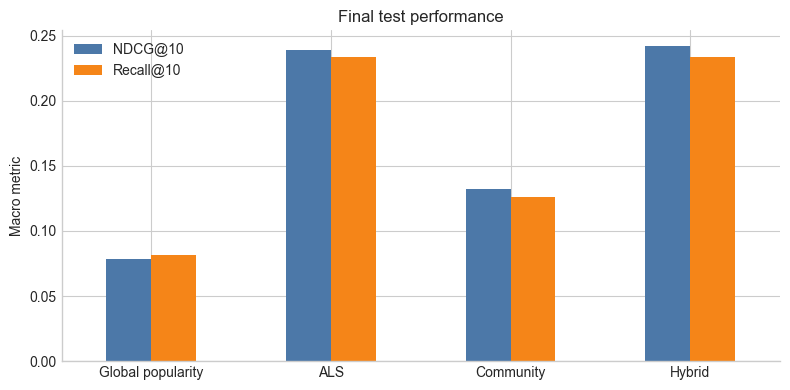

In [24]:
ax = test_metrics.set_index("method")[["NDCG@10", "Recall@10"]].plot.bar(
    figsize=(8, 4), color=["#4C78A8", "#F58518"])
ax.set(title="Final test performance", xlabel="", ylabel="Macro metric")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Paired bootstrap comparison

The main comparison uses each test user's Hybrid-minus-ALS NDCG@10 difference. I resample users with replacement 2,000 times and report the percentile confidence interval.

In [25]:
als_user = test_results["ALS"]["per_user"]
hybrid_user = test_results["Hybrid"]["per_user"]
differences = (hybrid_user.ndcg_at_10.to_numpy() - als_user.ndcg_at_10.to_numpy())

rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(differences), size=(2000, len(differences)))
bootstrap_means = differences[draws].mean(axis=1)
ci_lower, ci_upper = np.percentile(bootstrap_means, [2.5, 97.5])

bootstrap_result = pd.DataFrame({
    "comparison": ["Hybrid - ALS"],
    "mean NDCG@10 difference": [differences.mean()],
    "95% CI lower": [ci_lower],
    "95% CI upper": [ci_upper],
    "users": [len(differences)],
})
display(bootstrap_result.round(8))

,comparison,mean NDCG@10 difference,95% CI lower,95% CI upper,users
0,Hybrid - ALS,0.00257945,-0.00000753,0.00502635,1872


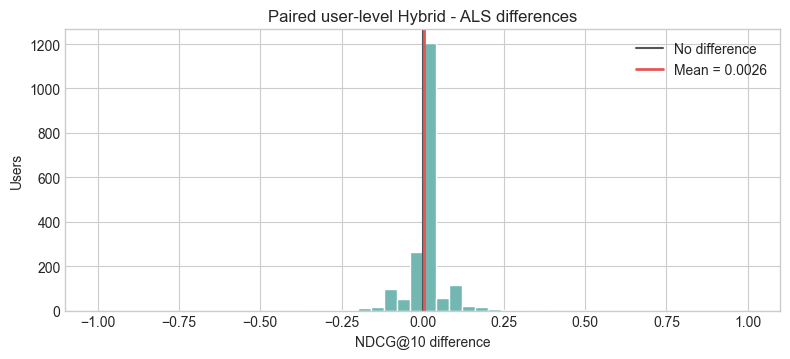

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.hist(differences, bins=np.linspace(-1, 1, 51), color="#72B7B2", edgecolor="white")
ax.axvline(0, color="#555555", label="No difference")
ax.axvline(differences.mean(), color="#E45756", linewidth=2,
           label=f"Mean = {differences.mean():.4f}")
ax.set(title="Paired user-level Hybrid - ALS differences",
       xlabel="NDCG@10 difference", ylabel="Users")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Listening similarity within communities

For a descriptive check, I compare training-set artist Jaccard similarity. Each eligible user is matched to one user in the same community and one in a different community, while keeping them in the same training-history band. Hash-based peer selection makes the matching reproducible.

In [27]:
def history_band(count):
    if count <= 10: return "5-10"
    if count <= 20: return "11-20"
    if count <= 50: return "21-50"
    return "51+"


def choose_peer(anchor, peers, kind):
    matching_namespace = "H1"
    return min(peers, key=lambda peer: (
        sha256(f"{SEED}|{matching_namespace}|{anchor}|{kind}|{peer}".encode("ascii")).digest(), peer))


training = split_table.query("split == 'train'")
artist_sets = {int(user): frozenset(group.artist_id)
               for user, group in training.groupby("user_id")}
bands = {user: history_band(len(values)) for user, values in artist_sets.items()}
labels = membership.set_index("user_id").community_id.to_dict()

In [28]:
similarity_rows = []
users = sorted(artist_sets)
for anchor in users:
    same = [peer for peer in users if peer != anchor and bands[peer] == bands[anchor]
            and labels[peer] == labels[anchor]]
    different = [peer for peer in users if bands[peer] == bands[anchor]
                 and labels[peer] != labels[anchor]]
    if not same or not different:
        continue
    same_peer = choose_peer(anchor, same, "within")
    different_peer = choose_peer(anchor, different, "cross")
    within = len(artist_sets[anchor] & artist_sets[same_peer]) / len(artist_sets[anchor] | artist_sets[same_peer])
    cross = len(artist_sets[anchor] & artist_sets[different_peer]) / len(artist_sets[anchor] | artist_sets[different_peer])
    similarity_rows.append((anchor, same_peer, different_peer, within, cross, within - cross))

similarity = pd.DataFrame(similarity_rows, columns=[
    "user_id", "same_peer", "different_peer", "within_jaccard", "cross_jaccard", "difference"])

In [29]:
def jackknife_similarity(table):
    involved_users = sorted(set(table.user_id) | set(table.same_peer) | set(table.different_peer))
    estimates = []
    for user_id in involved_users:
        keep = ((table.user_id != user_id) & (table.same_peer != user_id) &
                (table.different_peer != user_id))
        if keep.sum() >= 2:
            estimates.append(table.loc[keep, "difference"].mean())
    estimates = np.asarray(estimates)
    centre = estimates.mean()
    standard_error = np.sqrt((len(estimates) - 1) / len(estimates) *
                             np.square(estimates - centre).sum())
    estimate = table.difference.mean()
    return estimate, standard_error, estimate - 1.96 * standard_error, estimate + 1.96 * standard_error


similarity_estimate, similarity_se, similarity_lower, similarity_upper = jackknife_similarity(similarity)
similarity_result = pd.DataFrame({
    "matched users": [len(similarity)], "within mean": [similarity.within_jaccard.mean()],
    "cross mean": [similarity.cross_jaccard.mean()], "difference": [similarity_estimate],
    "95% lower": [similarity_lower], "95% upper": [similarity_upper],
})
display(similarity_result.round(8))

,matched users,within mean,cross mean,difference,95% lower,95% upper
0,1869,0.03382513,0.01364750,0.02017763,0.01613708,0.02421818


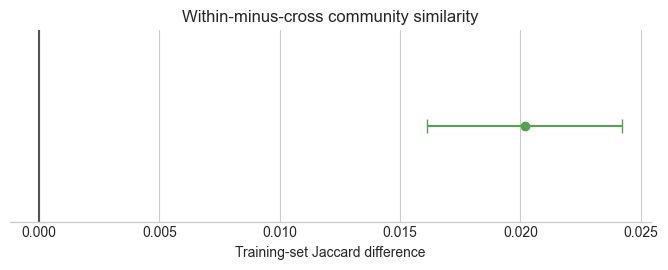

In [30]:
fig, ax = plt.subplots(figsize=(6.8, 2.8))
ax.errorbar([similarity_estimate], [0],
            xerr=[[similarity_estimate - similarity_lower],
                  [similarity_upper - similarity_estimate]],
            fmt="o", color="#54A24B", capsize=5)
ax.axvline(0, color="#555555")
ax.set(title="Within-minus-cross community similarity",
       xlabel="Training-set Jaccard difference", yticks=[])
ax.spines[["top", "right", "left"]].set_visible(False)
plt.tight_layout(); plt.show()

## 9. Robustness checks

I repeat the community calculations after shuffling community labels while preserving community sizes. I also expand candidates to the full artist catalog. The full-catalog version is a stress test because ALS has no learned factor for artists absent from the fitting data.

In [31]:
ordered_membership = membership.sort_values("user_id").reset_index(drop=True)
shuffled_users = ordered_membership.user_id.tolist()
random.Random(SEED).shuffle(shuffled_users)
label_lookup = ordered_membership.set_index("user_id").community_id
shuffled_membership = pd.DataFrame({
    "user_id": ordered_membership.user_id,
    "community_id": [int(label_lookup[user]) for user in shuffled_users],
})
shuffled_map = shuffled_membership.set_index("user_id").community_id.to_dict()

shuffled_community = fit_community_profile(test_phase["fit"], shuffled_membership, selected_beta)
shuffled_hybrid = fit_community_profile(test_phase["fit"], shuffled_membership, hybrid_beta)

In [32]:
shuffled_results = {
    "Shuffled community": evaluate(
        test_phase, lambda user, candidates:
        community_scores(shuffled_community, shuffled_map, user, candidates)),
    "Shuffled hybrid": evaluate(
        test_phase, lambda user, candidates: hybrid_scores(
            als_scores(final_als, user, candidates),
            community_scores(shuffled_hybrid, shuffled_map, user, candidates), selected_lambda)),
}

full_catalog_phase = build_phase(split_table, "test", artists.artist_id.tolist())
full_catalog_results = {name: evaluate(full_catalog_phase, scorer)
                        for name, scorer in scorers.items()}

In [33]:
robustness_rows = []
for name, result in shuffled_results.items():
    robustness_rows.append({"method": name, "candidate set": "Fit-observed artists",
                            "NDCG@10": result["ndcg_at_10"], "Recall@10": result["recall_at_10"],
                            "users": result["users"], "non-finite candidate scores": result["missing_scores"]})
for name, result in full_catalog_results.items():
    robustness_rows.append({"method": name, "candidate set": "Full catalog",
                            "NDCG@10": result["ndcg_at_10"], "Recall@10": result["recall_at_10"],
                            "users": result["users"], "non-finite candidate scores": result["missing_scores"]})

robustness = pd.DataFrame(robustness_rows)
display(robustness.round(8))

,method,candidate set,NDCG@10,Recall@10,users,non-finite candidate scores
0,Shuffled community,Fit-observed artists,0.07566747,0.07873041,1872,0
1,Shuffled hybrid,Fit-observed artists,0.23501889,0.22751450,1872,0
2,Global popularity,Full catalog,0.07490378,0.07629201,1876,0
3,ALS,Full catalog,0.22626691,0.21313331,1876,2954700
4,Community,Full catalog,0.12602422,0.11665398,1876,2954700
5,Hybrid,Full catalog,0.22893406,0.21332369,1876,2954700


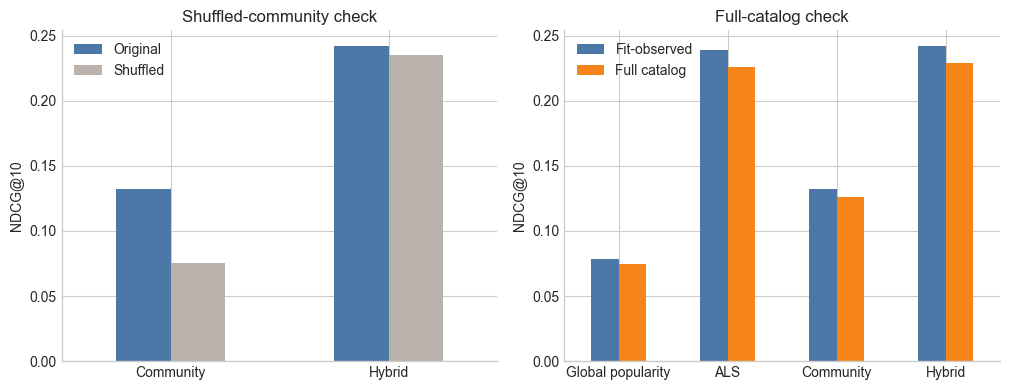

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4))
pd.DataFrame({
    "Original": [test_results["Community"]["ndcg_at_10"], test_results["Hybrid"]["ndcg_at_10"]],
    "Shuffled": [shuffled_results["Shuffled community"]["ndcg_at_10"],
                 shuffled_results["Shuffled hybrid"]["ndcg_at_10"]],
}, index=["Community", "Hybrid"]).plot.bar(ax=axes[0], color=["#4C78A8", "#BAB0AC"])

pd.DataFrame({
    "Fit-observed": [test_results[name]["ndcg_at_10"] for name in scorers],
    "Full catalog": [full_catalog_results[name]["ndcg_at_10"] for name in scorers],
}, index=list(scorers)).plot.bar(ax=axes[1], color=["#4C78A8", "#F58518"])
axes[0].set_title("Shuffled-community check"); axes[1].set_title("Full-catalog check")
for ax in axes:
    ax.set(xlabel="", ylabel="NDCG@10"); ax.tick_params(axis="x", rotation=0)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 10. Conclusion and limitations

The community-only model performs better than global popularity, and users matched within the same community have slightly more similar training artist sets than users matched across communities. The hybrid has a small positive test NDCG@10 difference from ALS, but the paired confidence interval reaches zero, so the improvement is uncertain.

The planned sparse-history comparison was not possible: the first-quartile cutoff is 35 training artists, but all 1,876 eligible users have 35 or fewer after this split, leaving no non-sparse comparison group. I kept the planned definition instead of changing it after seeing the data.

Other limitations are the non-temporal holdout, aggregate listening counts, static friendship links, and cold artists that cannot be represented by ALS. The results describe this historical sample and do not establish a causal effect of friendship.